In [ ]:
#Alice Wagner & Léandre Chaumeau

# D6 – Le problème à *n* corps

**Python numérique – projet de synthèse – séance 6 (mardi 20 octobre 2026)**

Bienvenue dans le projet de synthèse du cours ! Le sujet est un grand classique de la physique : des corps massifs s'attirent par gravitation, et nous voulons calculer puis tracer leurs trajectoires. Tout se passe dans le plan : chaque corps a une masse, une position `(x, y)` et une vitesse `(vx, vy)`.

Ce projet mobilise l'essentiel de ce que nous avons vu ensemble en NumPy : les tableaux multidimensionnels, le *broadcasting* de la séance 2, l'agrégation selon un axe, et `matplotlib` pour le tracé. Il est inspiré du TP « N-bodies » d'Aubin Geoffre et Thierry Parmentelat.

Le sujet comporte deux parties :

* la **partie A**, à faire en classe (comptez environ 1 h 30) : les quatre fonctions qui forment le cœur du projet. C'est elle qui est rendue **en fin de séance**.
* la **partie B**, des prolongements : vous ne l'abordez que si vous avez terminé la partie A — ou si le projet vous est donné à faire à la maison, auquel cas elle devient obligatoire et la date de rendu vous est indiquée par votre enseignant.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D6/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec sa figure à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) **avant de quitter la salle** (version en classe) ou à la date indiquée (version à la maison). Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* La figure `trajectoires.png` est enregistrée dans le dossier du notebook, et doit aussi apparaître dans le notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Le travail en **binôme est autorisé en classe** (un rendu par personne, avec les noms des deux dans la première cellule) ; la version à la maison, elle, est individuelle.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `numpy` / `matplotlib`, les notebooks du cours, vos notes, vos devoirs précédents.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**.
* En revanche, une boucle Python sur les corps est **interdite** dans `forces` : tout l'intérêt de l'exercice est de la remplacer par du *broadcasting*. La seule boucle autorisée est celle sur le temps, dans `simulate` — elle est en effet inévitable, puisque chaque pas dépend du précédent.
````

## Barème

| Partie | Contenu | Points |
|---|---|---|
| A1 | `init_problem` | 3 |
| A2 | Différences deux à deux (1D puis 2D) | 4 |
| A3 | `forces` vectorisée | 6 |
| A4 | `simulate` | 3 |
| A5 | `draw` + `trajectoires.png` + commentaire | 4 |
| **Total partie A** | | **20** |
| B | Prolongements (version à la maison : partie A / 14 + partie B / 6 ; en classe : bonus +2 max) | 6 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Partie A – en classe

### Conventions

Pour `N` corps, on manipule trois tableaux :

* `masses` de forme `(N,)` : `masses[i]` est la masse du corps `i` ;
* `positions` de forme `(2, N)` : `positions[:, i] = (x_i, y_i)` ; la ligne 0 contient tous les `x`, la ligne 1 tous les `y` ;
* `speeds` de forme `(2, N)` : `speeds[:, i] = (vx_i, vy_i)`.

Une configuration de test à trois corps vous est fournie ci-dessous : un "soleil" lourd immobile au centre, et deux satellites légers symétriques. Toutes les cellules de test s'appuient dessus : **ne la modifiez pas**.

In [2]:
def init3():
    """Trois corps : un soleil (masse 10) au centre, deux satellites (masse 1) symétriques."""
    masses = np.array([10.0, 1.0, 1.0])
    positions = np.array([[0.0, 5.0, -5.0],    # x
                          [0.0, 0.0, 0.0]])    # y
    speeds = np.array([[0.0, 0.0, 0.0],        # vx
                       [0.0, 1.4, -1.4]])      # vy
    return masses, positions, speeds

masses, positions, speeds = init3()
masses.shape, positions.shape, speeds.shape

((3,), (2, 3), (2, 3))

In [3]:
# bornes pour les tirages aléatoires de init_problem
MASS_MAX = 3.0
X_MIN, X_MAX = -10.0, 10.0
Y_MIN, Y_MAX = -10.0, 10.0
SPEED_MAX = 1.0

rng = np.random.default_rng(42)   # générateur « répétable »

### A1 – `init_problem(N)` (3 pts)

````{admonition} Pas encore vu en cours : np.vstack et np.stack
:class: note

`np.vstack([a, b])` empile deux tableaux de forme `(N,)` l'un au-dessus de l'autre et renvoie un tableau `(2, N)` : `np.vstack([[1, 2, 3], [4, 5, 6]])` vaut `[[1, 2, 3], [4, 5, 6]]`. `np.stack` fait la même chose mais laisse choisir l'axe d'empilement avec `axis=`. C'est la manière courante de recoller deux vecteurs de coordonnées `x` et `y` en un seul tableau à deux lignes.
````

Écrivez `init_problem(N)` qui renvoie un tuple `(masses, positions, speeds)` de formes `(N,)`, `(2, N)`, `(2, N)`, tiré au hasard avec les bornes ci-dessus :

* masses uniformes dans `]0, MASS_MAX]` (évitez la masse nulle : tirez dans `[0.1, MASS_MAX]`) ;
* positions uniformes dans le rectangle `[X_MIN, X_MAX] × [Y_MIN, Y_MAX]` ;
* vitesses : tirez un **angle** uniforme dans `[0, 2π[` et un **module** uniforme dans `[0, SPEED_MAX]`, puis projetez en `(cos, sin)`.

````{admonition} Indices
:class: tip

* `rng.uniform(a, b, size=...)` tire des valeurs uniformes entre `a` et `b`, à la forme demandée.
````

In [7]:
# votre code
def init_problem(N):
    #La borne supérieure est (sauf arrondi) exclu de rng.uniform d'après la documentation. On a cependant décidé de garder MASS_MAX et ne pas le remplacer par MASS_MAX+0.01.
    masses = rng.uniform(0.1, MASS_MAX, size=N)
    x,y = rng.uniform(X_MIN,X_MAX, size=N), rng.uniform(Y_MIN,Y_MAX, size=N)
    T, r = rng.uniform(0, 2*np.pi, size=N), rng.uniform(0,SPEED_MAX, size=N)
    vx, vy = r*np.cos(T), r*np.sin(T)
    return masses, np.vstack([x,y]), np.vstack([vx,vy])

In [8]:
# tests A1
m, p, s = init_problem(7)
assert m.shape == (7,) and p.shape == (2, 7) and s.shape == (2, 7)
assert np.all(m > 0) and np.all(m <= MASS_MAX)
assert np.all(p[0] >= X_MIN) and np.all(p[0] <= X_MAX)
assert np.all(np.linalg.norm(s, axis=0) <= SPEED_MAX + 1e-12)
print("A1 ok")

A1 ok


### A2 – Différences deux à deux (4 pts)

Avant de nous attaquer à la gravitation, travaillons le motif clé du projet : calculer toutes les différences `r_j − r_i` d'un seul coup, sans boucle, grâce au *broadcasting* vu en séance 2.

**A2.a – en 1D.** Soit un vecteur `x` de taille `N`. Construisez la matrice `D` de forme `(N, N)` telle que `D[i, j] = x[j] - x[i]`.

````{admonition} Indices
:class: tip

* Ajouter un axe à un vecteur avec `None` (`x[None, :]`, `x[:, None]`) change sa forme ; la règle « aligner par la droite » de la séance 2 fait le reste.
````

In [9]:
x = np.array([1.0, 4.0, 9.0])

In [10]:
# votre code
D = x[None, :] - x[:,None]
D

array([[ 0.,  3.,  8.],
       [-3.,  0.,  5.],
       [-8., -5.,  0.]])

In [11]:
# test A2.a
expected = np.array([[ 0.,  3.,  8.],
                     [-3.,  0.,  5.],
                     [-8., -5.,  0.]])
assert D.shape == (3, 3) and np.allclose(D, expected)
print("A2.a ok")

A2.a ok


**A2.b – en 2D.** Les positions sont maintenant un tableau `P` de forme `(2, N)`. Construisez le tableau `Delta` de forme `(2, N, N)` tel que `Delta[:, i, j] = P[:, j] - P[:, i]`, c'est-à-dire le vecteur qui va du corps `i` au corps `j`.

````{admonition} Indices
:class: tip

* Même idée qu'en A2.a, avec l'axe des coordonnées qui reste devant.
````

In [12]:
P = np.array([[0.0, 2.0, 5.0],    # x
              [0.0, 1.0, 4.0]])   # y      -> (2, 3)

In [13]:
# votre code
Delta = P[:, None, :] - P[:, :, None]
Delta

array([[[ 0.,  2.,  5.],
        [-2.,  0.,  3.],
        [-5., -3.,  0.]],

       [[ 0.,  1.,  4.],
        [-1.,  0.,  3.],
        [-4., -3.,  0.]]])

In [14]:
# test A2.b
assert Delta.shape == (2, 3, 3)
assert np.allclose(Delta[:, 0, 1], [2.0, 1.0])
assert np.allclose(Delta[:, 2, 0], [-5.0, -4.0])
assert np.allclose(Delta[:, 1, 1], [0.0, 0.0])
print("A2.b ok")

A2.b ok


````{admonition} Pas encore vu en cours : np.linalg.norm
:class: note

`np.linalg.norm(tab, axis=k)` calcule la norme euclidienne — la racine de la somme des carrés — le long de l'axe `k`, qui disparaît du résultat : sur un tableau `(2, N)` de coordonnées, `np.linalg.norm(tab, axis=0)` renvoie les `N` longueurs des vecteurs. C'est exactement `np.sqrt((tab ** 2).sum(axis=0))`, en plus court. Cette fonction vient du notebook optionnel `1-13` sur l'algèbre linéaire.
````

**A2.c – les distances.** À partir de `Delta`, calculez la matrice `dist` de forme `(N, N)` des distances `|r_j − r_i|`, **sans boucle**.

In [16]:
# votre code
dist = np.linalg.norm(Delta, axis=0)
dist

array([[0.        , 2.23606798, 6.40312424],
       [2.23606798, 0.        , 4.24264069],
       [6.40312424, 4.24264069, 0.        ]])

In [17]:
# test A2.c
assert dist.shape == (3, 3)
assert np.allclose(np.diag(dist), 0)
assert np.isclose(dist[0, 1], np.sqrt(5)) and np.isclose(dist[0, 2], np.sqrt(41))
print("A2.c ok")

A2.c ok


### A3 – `forces(masses, positions, G=1.0)` (6 pts)

````{admonition} Pas encore vu en cours : np.fill_diagonal
:class: note

`np.fill_diagonal(mat, valeur)` écrit `valeur` sur toute la diagonale d'une matrice carrée, **en place** : la fonction ne renvoie rien, elle modifie `mat`. Ainsi `np.fill_diagonal(m, 0)` annule tous les termes `m[i, i]`. C'est commode pour neutraliser les cas « `i` avec lui-même » dans une matrice de couples.
````

La force gravitationnelle subie par le corps `i` est

$$
\vec{F}_i = \sum_{j \ne i} G\, m_i\, m_j\, \frac{\vec{r}_j - \vec{r}_i}{\lVert \vec{r}_j - \vec{r}_i \rVert^3}
$$

Le contrat est le suivant : `forces(masses, positions, G=1.0)` renvoie un tableau de forme `(2, N)` contenant la force résultante sur chaque corps. **Aucune boucle** n'est autorisée ici : tout se fait par broadcasting, puis par une somme sur un axe.

````{admonition} Indices
:class: tip

* Reprenez le motif de l'exercice A2 : `Delta` et `dist`.
* La diagonale de `dist` vaut 0 : que va-t-il se passer au moment de diviser ? Rappelez-vous qu'un corps ne s'attire pas lui-même.
````

In [25]:
# votre code
def forces(masses, positions, G=1.0):
    Delta = positions[:,None,:] - positions[:,:,None]
    dist=np.linalg.norm(Delta, axis=0)
    np.fill_diagonal(dist, 1)
    M=masses[None, :]*masses[:,None]
    F= ((G * M[None,:,:] * Delta) / dist[None,:,:] ** 3).sum(axis=2)
    return F

In [26]:
# tests A3
masses, positions, speeds = init3()
f = forces(masses, positions)
assert f.shape == (2, 3)
assert np.allclose(f, [[0.0, -0.41, 0.41],
                       [0.0,  0.0,  0.0 ]]), f
# principe de l'action et de la réaction : la somme des forces est nulle
m, p, s = init_problem(5)
assert np.allclose(forces(m, p).sum(axis=1), 0)
print("A3 ok")

A3 ok


*Pourquoi `-0.41` ?* Le satellite en `x = 5` est attiré par le soleil (`10 × 1 / 25 = 0.4`) et par l'autre satellite (`1 × 1 / 100 = 0.01`), les deux vers la gauche. Vérifiez que vous retrouvez ce calcul de tête : c'est le meilleur test qui soit !

En effet, on retrouve bien le résultat de tête. :)

### A4 – `simulate(masses, positions, speeds, dt=0.1, nb_steps=100)` (3 pts)

On fait évoluer le système par la **méthode d'Euler** : à chaque pas de temps `dt`,

1. accélérations `a = F / m` (attention aux formes) ;
2. `speeds += a * dt` ;
3. `positions += speeds * dt`.

La fonction renvoie les positions à chaque pas, dans un tableau de forme `(nb_steps, 2, N)` (le pas 0 est la position initiale). C'est la seule boucle autorisée du projet : en effet, chaque pas dépend du précédent.

````{admonition} Indices
:class: tip

* Ne modifiez pas les tableaux passés en argument : commencez par `positions = positions.copy()` (et de même pour `speeds`). Rappelez-vous en effet la séance 1 : un tableau est passé *par référence*, et rappeler `init3()` plus tard ne vous sauvera pas si vous avez gardé les mêmes objets.
````

In [55]:
# votre code
def simulate(masses, positions, speeds, dt=0.1, nb_steps=100):
    positions = positions.copy()
    speeds = speeds.copy()
    trajectoire = np.zeros(shape=(nb_steps, 2, len(masses)))
    for i in range(nb_steps):
        trajectoire[i,:,:] = positions
        a = forces(masses, positions)/masses[None,:]
        speeds += a*dt
        positions += speeds*dt
    return trajectoire

In [56]:
# tests A4
masses, positions, speeds = init3()
traj = simulate(masses, positions, speeds)
assert traj.shape == (100, 2, 3)
assert np.allclose(traj[0], positions)            # pas 0 = position initiale
assert np.allclose(positions, init3()[1])          # l'argument n'a pas été modifié
assert np.allclose(traj[:, :, 0], 0)               # le soleil ne bouge pas (forces symétriques)
ref = np.loadtxt("data/init3-simu-dt0.1.txt").reshape((100, 2, 3))
assert np.allclose(traj, ref, atol=1e-6), "écart avec la simulation de référence"
print("A4 ok")

A4 ok


### A5 – `draw(traj, masses)` et `trajectoires.png` (4 pts)

Écrivez `draw(traj, masses, ax=None)` qui trace, pour chaque corps, tous ses points au fil du temps (une couleur par corps), et qui marque la position finale par un point dont la taille est proportionnelle à la masse. La fonction renvoie l'objet `Axes`.

Ici, une boucle sur les `N` corps est tout à fait acceptable : on trace `N` courbes.

````{admonition} Indices
:class: tip

* `traj[:, 0, k]` : tous les `x` du corps `k` au cours du temps.
* `ax.set_aspect("equal")` : sinon une orbite circulaire a l'air elliptique.
````

In [74]:
# votre code
def draw(traj, masses,  title, ax=None):
    N = len(masses)
    for i in range(N):
        ax.plot(traj[:,0,i], traj[:,1,i], label=f"Corps {i+1}")
        ax.scatter(traj[-1,0,i], traj[-1,1,i], s = 30*masses[i])
        ax.legend()
        ax.set_xlabel("Abscisses")
        ax.set_ylabel("Ordonnées")
        ax.set_aspect("equal")
        ax.set_title(title)
    return ax

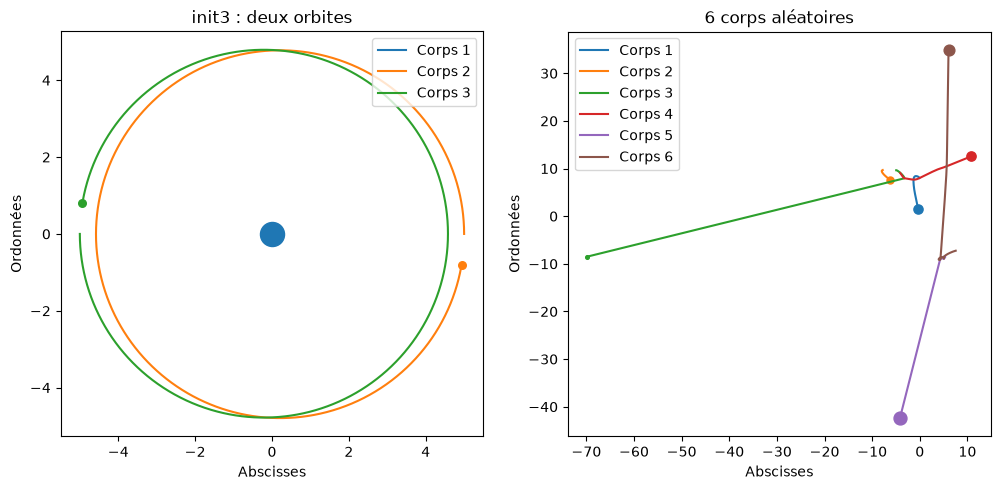

In [75]:
# test A5 : deux figures côte à côte, la config de test et une config aléatoire
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
masses, positions, speeds = init3()
draw(simulate(masses, positions, speeds, dt=0.01, nb_steps=2000), masses, ax=axes[0], title="init3 : deux orbites")
m, p, s = init_problem(6)
draw(simulate(m, p, s, dt=0.05, nb_steps=200), m, ax=axes[1], title="6 corps aléatoires")
fig.savefig("trajectoires.png", dpi=120, bbox_inches="tight")

**Question A5** (répondez dans la cellule ci-dessous). Lancez `simulate(*init3(), dt=0.1, nb_steps=100)` puis `dt=0.01, nb_steps=1000` (même durée simulée). Comparez les positions finales (`traj[-1]`) : elles diffèrent ! Pouvez-vous expliquer pourquoi ? Et que se passe-t-il si deux corps passent très près l'un de l'autre ?

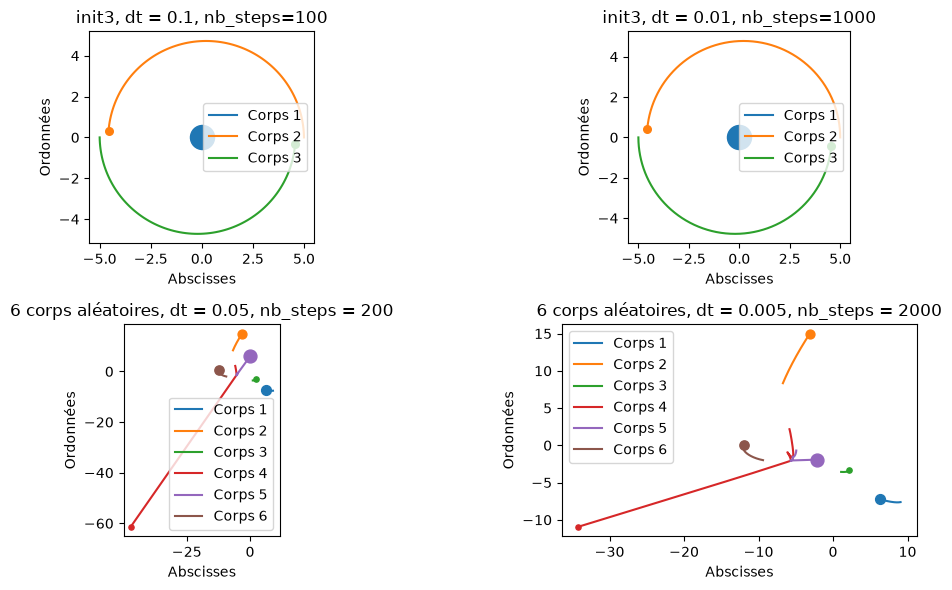

[[ 0.         -4.56666954  4.56666954]
 [ 0.          0.3181649  -0.3181649 ]] 
 [[ 0.         -4.56003572  4.56003572]
 [ 0.          0.42414426 -0.42414426]]


In [77]:
# votre code
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
draw(simulate(*init3(), dt=0.1, nb_steps=100), masses, ax=axes[0,0], title="init3, dt = 0.1, nb_steps=100")
draw(simulate(*init3(), dt=0.01, nb_steps=1000), masses, ax=axes[0,1], title="init3, dt = 0.01, nb_steps=1000")
traj1 = simulate(*init3(), dt=0.1, nb_steps=100)
traj2 = simulate(*init3(), dt=0.01, nb_steps=1000)
m, p, s = init_problem(6)
draw(simulate(m, p, s, dt=0.05, nb_steps=200), m, ax=axes[1,0], title="6 corps aléatoires, dt = 0.05, nb_steps = 200")
draw(simulate(m, p, s, dt=0.005, nb_steps=2000), m, ax=axes[1,1], title="6 corps aléatoires, dt = 0.005, nb_steps = 2000")
fig.tight_layout()
plt.show()
print(traj1[-1], "\n", traj2[-1])

*Réponse :* On a une différence de l'ordre de 0.001 à 0.1. Elle est dû aux erreurs d'approximation lié au calcul de flottants. D'autant plus, lorsque deux corps passent l'un près de l'autre, alors la force en 1/r² explose et un facteur d'erreur de 0.1 peut faire varier significativement les calculs. Comme on peut le voir sur les deux trajectoires avec 6 corps aléatoires (relancer plusieurs fois si besoin)

Vous voici au bout de la partie A ! En classe, prenez le temps d'un dernier *Restart Kernel and Run All Cells*, vérifiez que `trajectoires.png` est bien là, puis rendez le notebook.

## Partie B – prolongements

*Cette partie est obligatoire dans la version "à la maison" ; en classe, elle compte en bonus pour ceux qui ont fini.*

### B1 – L'énergie, un test de qualité (2 pts)

L'énergie mécanique totale $E = \sum_i \tfrac12 m_i \lVert v_i \rVert^2 - \sum_{i<j} G \frac{m_i m_j}{\lVert r_j - r_i \rVert}$ devrait être conservée au cours du temps. Or, Euler ne la conserve pas : c'est un excellent moyen de mesurer la qualité d'une simulation.

1. Écrivez `energy(masses, positions, speeds, G=1.0)` **sans boucle** (réutilisez `Delta`/`dist` ; attention à ne compter chaque paire qu'une fois).
2. Modifiez `simulate` en `simulate2` pour qu'elle renvoie aussi l'énergie à chaque pas (forme `(nb_steps,)`), et tracez `E(t)` pour `init3()` avec `dt = 0.1` et `dt = 0.01`. Commentez.

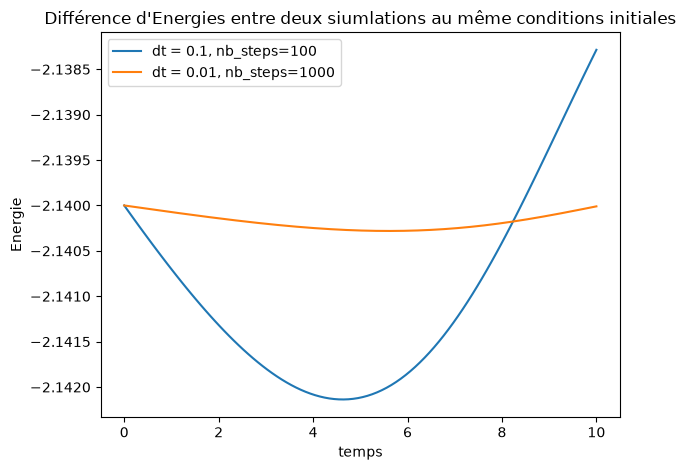

In [94]:
# votre code
def energy(masses, positions, speeds, G=1.0):
    Delta = positions[:,None,:] - positions[:,:,None]
    dist=np.linalg.norm(Delta, axis=0)

    v = np.linalg.norm(speeds, axis=0)
    np.fill_diagonal(dist,np.inf)
    M=masses[None, :]*masses[:,None]

    Ec = (1/2 * masses * v**2).sum()
    Ep = -1/2 * (G * M/dist).sum()
    return Ec+Ep

def simulate2(masses, positions, speeds, dt=0.1, nb_steps=100):
    positions = positions.copy()
    speeds = speeds.copy()
    energies = np.zeros((nb_steps,))
    trajectoire = np.zeros(shape=(nb_steps, 2, len(masses)))
    for i in range(nb_steps):
        trajectoire[i,:,:] = positions
        energies[i] = energy(masses, positions, speeds)
        a = forces(masses, positions)/masses[None,:]
        speeds += a*dt
        positions += speeds*dt
    return trajectoire, energies

_, E1 = simulate2(*init3(), dt=0.1, nb_steps=100)
_, E2 = simulate2(*init3(), dt=0.01, nb_steps=1000)
t1 = np.linspace(0,10, 100)
t2 = np.linspace(0, 10, 1000)
plt.plot(t1, E1, label="dt = 0.1, nb_steps=100")
plt.plot(t2, E2, label="dt = 0.01, nb_steps=1000")
plt.legend()
plt.title("Différence d'Energies entre deux siumlations au même conditions initiales")
plt.ylabel("Energie")
plt.xlabel("temps")
plt.tight_layout()
plt.show()

On remarque que lorsque le dt est plus petit, l'énergie est plus constante.

In [87]:
# test B1
assert np.isclose(energy(*init3()), -2.14)
print("B1 ok")

B1 ok


### B2 – Un meilleur intégrateur : leapfrog (2 pts)

Le schéma "saute-mouton" (*leapfrog*, ou Euler symplectique) change une ligne : on met à jour la vitesse *puis* la position avec la nouvelle vitesse — c'est déjà ce que fait notre `simulate` ! La version complète, d'ordre 2, est la suivante :

1. `speeds += a(positions) * dt / 2` (demi-pas)
2. `positions += speeds * dt`
3. `speeds += a(positions) * dt / 2` (demi-pas, avec les nouvelles forces)

Écrivez `simulate_leapfrog` (même contrat que `simulate2`), et superposez `E(t)` pour Euler et leapfrog à `dt = 0.1` sur `init3()`, 2000 pas. Que constatez-vous ?

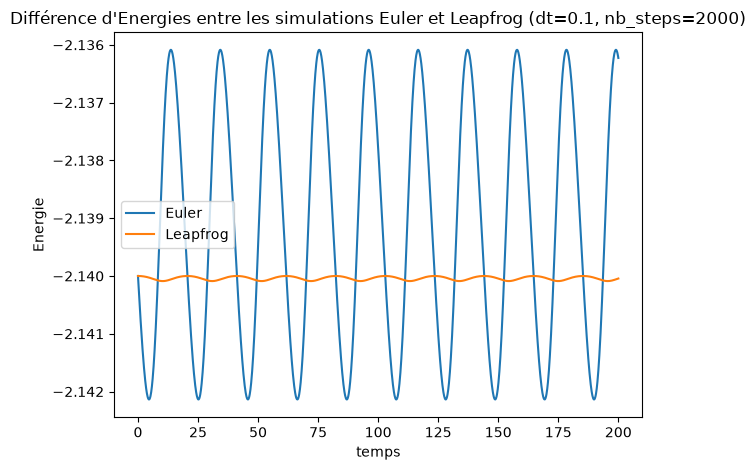

B2 ok


In [98]:
# votre code
def simulate_leapfrog(masses, positions, speeds, dt=0.1, nb_steps=100):
    positions = positions.copy()
    speeds = speeds.copy()
    energies = np.zeros((nb_steps,))
    trajectoire = np.zeros(shape=(nb_steps, 2, len(masses)))
    def a(positions) : 
        return forces(masses, positions)/masses[None,:]
    for i in range(nb_steps):
        trajectoire[i,:,:] = positions
        energies[i] = energy(masses, positions, speeds)
        speeds += (a(positions)*dt)/2
        positions += speeds*dt
        speeds += (a(positions)*dt)/2
    return trajectoire, energies

t = np.linspace(0,200, 2000)
_, E_euler = simulate2(*init3(), dt=0.1, nb_steps = 2000)
plt.plot(t, E_euler, label="Euler")
_, E_leap = simulate_leapfrog(*init3(), dt=0.1, nb_steps = 2000)
plt.plot(t, E_leap, label="Leapfrog")
plt.legend()
plt.title("Différence d'Energies entre les simulations Euler et Leapfrog (dt=0.1, nb_steps=2000)")
plt.ylabel("Energie")
plt.xlabel("temps")
plt.tight_layout()
plt.show()

print("B2 ok")

*Réponse :* On remarque que la simulation Leapfrog est beaucoup pus efficace que Euler pour conserver l'énergie. Ce qui traduit d'une simulation plus efficace.

### B3 – Passer à l'échelle (2 pts)

````{admonition} Pas encore vu en cours : l'échelle logarithmique
:class: note

`ax.loglog(x, y, "o-")` trace comme `ax.plot` mais avec les deux axes en échelle logarithmique (équivalent : `ax.set_xscale("log")` et `ax.set_yscale("log")`). Une loi de puissance $y = C\,x^a$ y apparaît comme une droite de pente $a$, ce qui permet de lire un exposant à l'œil.
````

1. Mesurez (`%timeit`) le temps d'un appel à `forces` pour `N = 10, 100, 1000` corps (`init_problem(N)`). Tracez le temps en fonction de `N` en échelle log-log. Quelle est la pente ? Pourquoi ?
2. Écrivez une version `forces_boucles` avec deux boucles `for` imbriquées sur `i` et `j`, vérifiez qu'elle donne le même résultat que `forces` sur `init3()` (`np.allclose`), et comparez les temps pour `N = 100`. Combien de fois plus lente ?

20.4 μs ± 2.08 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
391 μs ± 17.6 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
275 μs ± 24.5 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
39.3 ms ± 1.88 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
42.3 ms ± 854 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
3.92 s ± 73.8 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


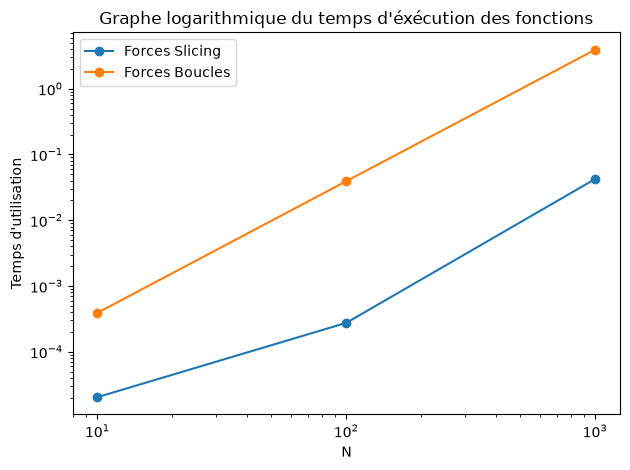

In [121]:
# votre code
def forces_boucles(masses, positions, G=1.0):
    N = len(masses)
    F = np.zeros((2,N))
    for i in range(N):
        f_i = 0
        for j in range(N):
            if j !=i :
                F[:,i] = F[:,i]+ G*masses[i]*masses[j] / np.sqrt((positions[0,j]-positions[0,i])**2 + (positions[1,j]-positions[1,i])**2)**3 * np.array([positions[0,j]-positions[0,i], positions[1,j]-positions[1,i]])
    return F

l_N = [10, 100, 1000]
t_N = []
tb_N = []
for N in l_N:
    mas_n, pos_n, _ = init_problem(N)
    t = %timeit -o f = forces(mas_n, pos_n)
    t_b = %timeit -o fb = forces_boucles(mas_n, pos_n)
    tb_N.append(t_b.average)
    t_N.append(t.average)
plt.loglog(l_N, t_N, "-o", label="Forces Slicing")
plt.loglog(l_N,tb_N, "-o", label="Forces Boucles")
plt.title("Graphe logarithmique du temps d'éxécution des fonctions")
plt.xlabel("N")
plt.ylabel("Temps d'utilisation")
plt.legend()
plt.tight_layout()
plt.show()

*Réponse :* Le temps d'éxécution est décalé linéairement entre les deux éxécutions, il y a donc un facteur multiplicatif entre (puisque nous sommes en graphe loglog). Le graphe de forces boucles est effectivement une ligne droite de pente 2 ce qui correspond à une complexité en O(n²). Celui de forces slicing est toujours inférieur à boucles mais semble se dirigé vers une complexité en O(n²) lorsque N augmente. Pour N = 100, on a timeit qui renvoie en moyenne : 275 microsecondes pour slicing et 39.3 milisecondes pour boucles. On a donc un facteur ~100 entre les deux.

Et voilà, le projet est terminé ! Un dernier *Restart Kernel and Run All Cells*, vérifiez que `trajectoires.png` est bien à côté du notebook, puis commitez et **poussez** le dossier `D6/` de votre dépôt `pe-homework`.

Bon courage à tous ! Pour toute question sur le sujet, écrivez-moi à [aurelien.noce@minesparis.psl.eu](mailto:aurelien.noce@minesparis.psl.eu), en mettant [aurelien.noce@imagine-app.fr](mailto:aurelien.noce@imagine-app.fr) en copie : la messagerie de l'école perd parfois des mails, la seconde adresse sert de filet.

Au plaisir de vous lire,

votre responsable de cours, Aurélien Noce